# 07 - Dense neural network
Same 14 sensors as the tree models (single time-step), capped + scaled target, early stopping. Saved as `models/dense_model.keras`.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find the project root (the folder containing utils.py) no matter where the kernel was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
import utils as U

In [2]:
ds = U.load_dataset()               # features, capped targets, engine-wise train/val split, official test targets
tr = ~ds.is_val
print("train rows:", tr.sum(), "| val rows:", ds.is_val.sum(), "| test engines:", len(ds.y_test))

train rows: 16138 | val rows: 4493 | test engines: 100


In [3]:
def report(name, val_pred, test_pred):
    """Validation = all rows of the 20 held-out training engines (capped RUL).
    Test = official protocol: ONE prediction per test engine (last observed cycle) vs RUL_FD001."""
    v = U.score_predictions(ds.y_train[ds.is_val], val_pred)
    t = U.score_predictions(ds.y_test, test_pred)
    print(f"{name}\n  validation  RMSE {v['RMSE']:.2f}  MAE {v['MAE']:.2f}  R2 {v['R2']:.3f}")
    print(f"  test (official)  RMSE {t['RMSE']:.2f}  MAE {t['MAE']:.2f}  R2 {t['R2']:.3f}  NASA score {t['NASA']:.0f}")
    return t

def scatter(test_pred, title):
    plt.figure(figsize=(5, 5))
    plt.scatter(ds.y_test, test_pred, alpha=0.7)
    lim = max(ds.y_test.max(), test_pred.max()) + 5
    plt.plot([0, lim], [0, lim], "r--"); plt.xlabel("True RUL"); plt.ylabel("Predicted RUL")
    plt.title(title); plt.grid(alpha=0.3); plt.show()

base = U.score_predictions(ds.y_test, np.full(len(ds.y_test), ds.train_mean_rul))
print(f"Reference - always predicting the mean training RUL: test RMSE {base['RMSE']:.2f}")

Reference - always predicting the mean training RUL: test RMSE 52.62


In [4]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)
CALLBACKS = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5),
]
# The networks learn RUL / RUL_CAP (range 0..1). utils.load_saved_models multiplies the output back.
y_nn = ds.y_train / U.RUL_CAP

2026-11-19 13:26:07.132835: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-19 13:26:07.873069: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-19 13:26:10.262287: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [5]:
Xtr = ds.X_train.tab.to_numpy("float32")
model = keras.Sequential([
    layers.Input(shape=(len(U.FEATURES),)),
    layers.Dense(64, activation="relu"), layers.Dropout(0.1),
    layers.Dense(32, activation="relu"),
    layers.Dense(1),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")

hist = model.fit(Xtr[tr], y_nn[tr], validation_data=(Xtr[ds.is_val], y_nn[ds.is_val]),
                 epochs=150, batch_size=256, callbacks=CALLBACKS, verbose=2)

W0000 00:00:1795082171.794867    7313 gpu_device.cc:2342] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Epoch 1/150
64/64 - 1s - 20ms/step - loss: 0.0926 - val_loss: 0.0488 - learning_rate: 0.0010
Epoch 2/150
64/64 - 0s - 3ms/step - loss: 0.0464 - val_loss: 0.0376 - learning_rate: 0.0010
Epoch 3/150
64/64 - 0s - 5ms/step - loss: 0.0375 - val_loss: 0.0325 - learning_rate: 0.0010
Epoch 4/150
64/64 - 0s - 3ms/step - loss: 0.0326 - val_loss: 0.0291 - learning_rate: 0.0010
Epoch 5/150
64/64 - 0s - 3ms/step - loss: 0.0291 - val_loss: 0.0268 - learning_rate: 0.0010
Epoch 6/150
64/64 - 0s - 3ms/step - loss: 0.0271 - val_loss: 0.0264 - learning_rate: 0.0010
Epoch 7/150
64/64 - 0s - 3ms/step - loss: 0.0256 - val_loss: 0.0252 - learning_rate: 0.0010
Epoch 8/150
64/64 - 0s - 3ms/step - loss: 0.0244 - val_loss: 0.0245 - learning_rate: 0.0010
Epoch 9/150
64/64 - 0s - 3ms/step - loss: 0.0238 - val_loss: 0.0243 - learning_rate: 0.0010
Epoch 10/150
64/64 - 0s - 3ms/step - loss: 0.0232 - val_loss: 0.0241 - learning_rate: 0.0010
Epoch 11/150
64/64 - 0s - 3ms/step - loss: 0.0230 - val_loss: 0.0236 - learnin

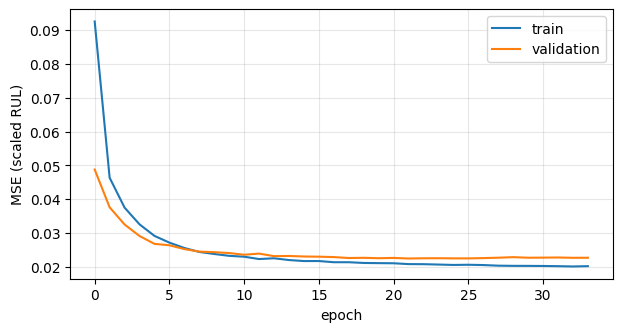

In [6]:
plt.figure(figsize=(7, 3.5))
plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("MSE (scaled RUL)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

Dense NN
  validation  RMSE 18.73  MAE 14.20  R2 0.794
  test (official)  RMSE 17.92  MAE 13.35  R2 0.814  NASA score 793


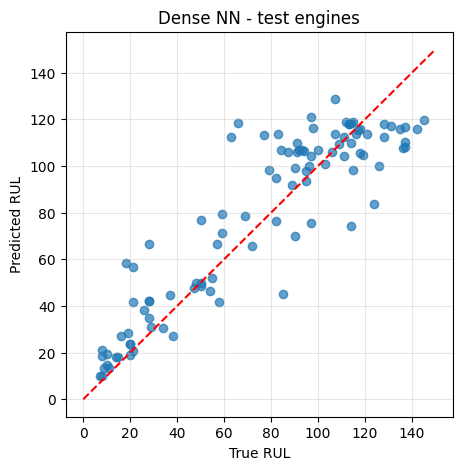

In [7]:
val_pred  = np.clip(model.predict(Xtr[ds.is_val], verbose=0).ravel() * U.RUL_CAP, 0, None)
test_pred = np.clip(model.predict(ds.X_test.tab.iloc[ds.last_idx].to_numpy("float32"), verbose=0).ravel() * U.RUL_CAP, 0, None)
report("Dense NN", val_pred, test_pred)
scatter(test_pred, "Dense NN - test engines")
model.save(U.MODEL_DIR / "dense_model.keras")